# Model Comparison

Three candidates on identical data:

| model | notebook |
|---|---|
| Random forest, 500 trees | `thyroid.ipynb` |
| Decision tree, depth 3 | `decision_tree.ipynb` |
| SVM, RBF kernel | `svm.ipynb` |

Scored with repeated cross-validation rather than one split, because the test set holds only
58 hypothyroid patients and a single patient is 1.7% of recall.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (FunctionTransformer, LabelEncoder, StandardScaler)
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_validate, train_test_split)

CSV = "../dataset/hypothyroid.csv"
FEATURES = ["age", "sex", "TSH", "TT4", "T4U", "FTI"]
TARGET = "binaryClass"
CLASS_NAMES = ["negative", "hypothyroid"]
RANDOM_STATE = 42

## Data

In [2]:
# Same cleaning as thyroid.ipynb section 3.
df = pd.read_csv(CSV, na_values="?")[FEATURES + [TARGET]]

known = df["sex"].notna()
df.loc[known, "sex"] = LabelEncoder().fit_transform(df.loc[known, "sex"])
df["sex"] = df["sex"].astype(float)

# LabelEncoder puts "N" first, and "N" is the hypothyroid group, so flip it.
df[TARGET] = 1 - LabelEncoder().fit_transform(df[TARGET])

clean = df[~(df["age"] > 120)].drop_duplicates()
X = clean[FEATURES]
y = clean[TARGET]
print(f"{len(clean)} patients, {y.sum()} hypothyroid ({100 * y.mean():.2f}%)")
clean.head()

3658 patients, 291 hypothyroid (7.96%)


,age,sex,TSH,TT4,T4U,FTI,binaryClass
0,41.0,0.0,1.30,125.0,1.14,109.0,0
1,23.0,0.0,4.10,102.0,NaN,NaN,0
2,46.0,1.0,0.98,109.0,0.91,120.0,0
3,70.0,0.0,0.16,175.0,NaN,NaN,0
4,70.0,0.0,0.72,61.0,0.87,70.0,0


## The three models

The SVM carries its preprocessing inside a pipeline — `log1p(TSH)`, median imputation and
scaling — so every fold stays leak-free. The tree models need none of it: they split on rank,
and scikit-learn lets them read `NaN` directly.

In [3]:
log_tsh = ColumnTransformer([("log", FunctionTransformer(np.log1p), ["TSH"])],
                            remainder="passthrough")

MODELS = {
    "Random forest": RandomForestClassifier(
        n_estimators=500, min_samples_leaf=2, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1),
    "Decision tree (d3)": DecisionTreeClassifier(
        max_depth=3, class_weight="balanced", random_state=RANDOM_STATE),
    "SVM (RBF, C=10)": make_pipeline(
        log_tsh, SimpleImputer(strategy="median"), StandardScaler(),
        CalibratedClassifierCV(
            SVC(C=10, class_weight="balanced", random_state=RANDOM_STATE), ensemble=False)),
}
list(MODELS)

['Random forest', 'Decision tree (d3)', 'SVM (RBF, C=10)']

## 1. Repeated cross-validation (25 fits per model)

In [4]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
raw = {}
rows = []
for name, model in MODELS.items():
    r = cross_validate(model, X, y, cv=cv, n_jobs=-1,
                       scoring=["average_precision", "recall", "precision"])
    raw[name] = r
    rows.append({
        "model": name,
        "avg_precision": f"{r['test_average_precision'].mean():.4f} ± {r['test_average_precision'].std():.4f}",
        "recall": f"{r['test_recall'].mean():.4f} ± {r['test_recall'].std():.4f}",
        "precision": f"{r['test_precision'].mean():.4f} ± {r['test_precision'].std():.4f}",
    })
pd.DataFrame(rows).set_index("model")

,avg_precision,recall,precision
model,,,
Random forest,0.8935 ± 0.0350,0.9931 ± 0.0097,0.8068 ± 0.0338
Decision tree (d3),0.8073 ± 0.0402,0.9897 ± 0.0137,0.7943 ± 0.0332
"SVM (RBF, C=10)",0.8304 ± 0.0527,0.8344 ± 0.0538,0.8027 ± 0.0452


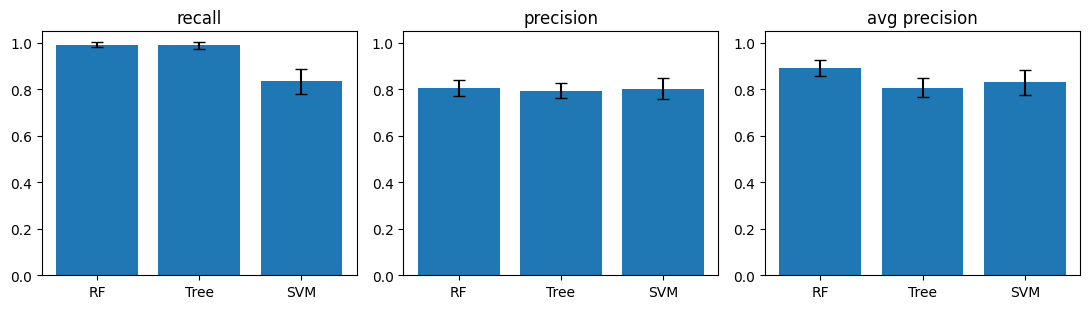

In [5]:
metrics = [("test_recall", "recall"), ("test_precision", "precision"),
           ("test_average_precision", "avg precision")]
names = list(MODELS)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, (key, title) in zip(axes, metrics):
    means = [raw[n][key].mean() for n in names]
    stds = [raw[n][key].std() for n in names]
    ax.bar(range(3), means, yerr=stds, capsize=4)
    ax.set_xticks(range(3), ["RF", "Tree", "SVM"])
    ax.set_ylim(0, 1.05)
    ax.set_title(title)
plt.tight_layout()
plt.show()

Recall is the panel that decides this: it is the share of hypothyroid patients actually caught,
and a missed patient is the expensive error.

## 2. How many distinct scores each model produces

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
positives = int((y_test == 1).sum())

scores = {}
for name, model in MODELS.items():
    model.fit(X_train, y_train)
    scores[name] = model.predict_proba(X_test)[:, 1]
    print(f"{name:20s} distinct predicted scores: {len(np.unique(scores[name])):4d}")

Random forest        distinct predicted scores:  367
Decision tree (d3)   distinct predicted scores:    3
SVM (RBF, C=10)      distinct predicted scores:  732


A model with few distinct scores cannot have its threshold tuned, which is most of the
average-precision gap. The fair comparison is at a **matched operating point**: the lowest
threshold that still reaches 95% recall, judged on what it costs in false alarms.

In [7]:
rows = []
for name, s in scores.items():
    for t in np.unique(np.r_[s, 1.0])[::-1]:
        recall = ((s >= t) & (y_test == 1)).sum() / positives
        if recall >= 0.95:
            rows.append({"model": name, "threshold": round(t, 3), "recall": round(recall, 4),
                         "missed": int(((s < t) & (y_test == 1)).sum()),
                         "false_alarms": int(((s >= t) & (y_test == 0)).sum())})
            break
pd.DataFrame(rows).set_index("model")

,threshold,recall,missed,false_alarms
model,,,,
Random forest,0.674,0.9655,2,9
Decision tree (d3),0.980,0.9828,1,9
"SVM (RBF, C=10)",0.241,0.9655,2,20


## 3. Criteria that are not performance

In [8]:
pd.DataFrame([
    {"criterion": "recall (25-fit CV)",
     **{n: f"{raw[n]['test_recall'].mean():.4f}" for n in names}},
    {"criterion": "distinct scores",
     **{n: str(len(np.unique(scores[n]))) for n in names}},
    {"criterion": "mean fit time",
     **{n: f"{raw[n]['fit_time'].mean():.3f} s" for n in names}},
    {"criterion": "reads missing tests",
     **{n: "no, imputes" if "SVM" in n else "yes" for n in names}},
    {"criterion": "readable by hand",
     **{n: "yes" if "tree" in n.lower() and "forest" not in n.lower() else "no" for n in names}},
]).set_index("criterion")

,Random forest,Decision tree (d3),"SVM (RBF, C=10)"
criterion,,,
recall (25-fit CV),0.9931,0.9897,0.8344
distinct scores,367,3,732
mean fit time,0.855 s,0.003 s,0.115 s
reads missing tests,yes,yes,"no, imputes"
readable by hand,no,yes,no
